# Top molecules viewer

Set `CSV_PATH` to a molecule-snapshot or scored CSV, then run all cells.
Re-scores each top molecule with the current CO2 objective and prints every metric.

Hard gate is **charge 0**, atoms in `{C,H,N,O,F,S}`, **no sulfonyl**, **one fragment**.
`n_ha` and `n_amine` are still reported: HAE multiplier uses `n_ha`; OH penalty uses `n_amine`.


In [36]:
from pathlib import Path

ROOT = Path("/home/ashtondy/Work/Kostas/Molecule_Generation_Workflow")
CSV_PATH = ROOT / "outputs/druglike_dstar_arms_uncapped/no_tether/20260909_182447_druglike/molecule_snapshots/ep1000.csv"
TOP_N = 10
MOLS_PER_ROW = 5


In [37]:
import os
import sys

import pandas as pd
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw

sys.path.insert(0, str(ROOT))
os.environ.setdefault("MGW_OBJECTIVE", "co2")

from objectives.co2_rl_helpers import (
    amine_floor_excess,
    amine_justified_oh_excess,
    azacrown_bonus_units,
    co2_gate_ok,
    count_amine_n,
    count_oh,
    count_rotatable_bonds,
    hae_multiplier,
    hae_raw,
    high_end_excess,
    max_consecutive_rotatable_bonds,
    mw_excess,
    mw_scale,
    nn_distance_excess,
    nonbasic_n_excess,
    rot_window_excess,
    substructure_alert_excesses,
    vicinal_diamine_diol,
)
from objectives.co2_reward import (
    AMINE_FLOOR,
    ACETAL_FREE,
    RING_O_FREE,
    SULFUR_FREE,
    W_ACETAL_PENALTY,
    W_ALKYNE_PENALTY,
    W_AMIDE_PENALTY,
    W_AMINAL_PENALTY,
    W_AZACROWN_BONUS,
    W_EPOXIDE_PENALTY,
    W_ESTER_PENALTY,
    W_FURAN_PENALTY,
    W_HEMIAMINAL_PENALTY,
    W_HINDERED_AMINE_PENALTY,
    W_HYDRATE_PENALTY,
    W_NONBASIC_N_PENALTY,
    W_RING_O_PENALTY,
    W_SULFUR_PENALTY,
    CONSEC_ROT_FULL_HI,
    CONSEC_ROT_ZERO_HI,
    HAE_MULT_HI,
    HAE_MULT_LO,
    MW_FLAT_HI,
    MW_FLAT_LO,
    MW_SCALE_HI,
    MW_SCALE_LO,
    NN_DIST_THRESH,
    OH_AMINE_FREE,
    ROT_WINDOW_HI,
    ROT_WINDOW_LO,
    SA_SCALE_FULL_HI,
    SA_SCALE_ZERO_HI,
    W_AMINE_FLOOR_PENALTY,
    W_APOL,
    W_BASICITY,
    W_CONSEC_ROT_PENALTY,
    W_DIVERSE,
    W_HAE_ALPHA,
    W_HALL_KIER_ALPHA,
    W_LOGP,
    W_MW_PENALTY,
    W_NN_PENALTY,
    W_OH_PENALTY,
    W_PFC_COMPOSITE,
    W_ROT_WINDOW_PENALTY,
    W_SA_PENALTY,
    W_TPSA,
    W_VICINAL_DIOL_BONUS,
    CO2ObjectiveScorer,
    _embed_min_nn_distance,
    _safe,
    _make_mordred_calculator,
    term_score,
    zscore_key,
)

scorer = CO2ObjectiveScorer(
    n_conformers=2,
    n_workers=0,
    use_scaffold_filter=False,
)
calc = _make_mordred_calculator()
ceil = bool(scorer.use_objective_ceilings) and not bool(scorer.use_sigmoid_reward)
sig = bool(scorer.use_sigmoid_reward)


In [38]:
def score_one(smi: str, diversity_term: float) -> dict:
    """Full CO2 metric breakdown for one SMILES (diversity_term from batch)."""
    row = {"smiles": smi, "reward": float("nan")}
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        row["valid"] = False
        return row

    row["valid"] = True
    can = Chem.MolToSmiles(mol)
    row["canonical"] = can
    n_ha = int(mol.GetNumHeavyAtoms())
    n_amine = int(count_amine_n(mol))
    n_oh = int(count_oh(mol))
    row["n_ha"] = n_ha
    row["n_amine"] = n_amine
    row["n_oh"] = n_oh
    # Hard gate: charge 0, {C,H,N,O,F,S}, no sulfonyl, one fragment.
    row["gate_ok"] = co2_gate_ok(mol)
    if not row["gate_ok"]:
        return row

    mw = float(Descriptors.MolWt(mol))
    logp = float(Descriptors.MolLogP(mol))
    alpha = float(Descriptors.HallKierAlpha(mol))
    result = calc(mol)
    apol = float(result["apol"])
    tpsa = float(result["TopoPSA(NO)"])
    basicity = (
        _safe(result["SaaN"])
        + _safe(result["SdNH"])
        + _safe(result["SsNH2"])
        + _safe(result["SssNH"])
        + _safe(result["SsOH"])
    )

    min_nn = float("nan")
    try:
        if scorer.include_pfc:
            pfc_out = scorer.pfc.compute(smi)
            pfc_raw = float(pfc_out["composite"])
            min_nn = float(pfc_out.get("min_nn_distance", float("nan")))
        else:
            pfc_raw = float("nan")
            min_nn = float(_embed_min_nn_distance(smi))
    except Exception:
        pfc_raw = float("nan")

    apol_t = term_score(apol, "apol", use_sigmoid=sig, use_ceilings=ceil)
    tpsa_t = term_score(tpsa, "TopoPSA", use_sigmoid=sig, use_ceilings=ceil)
    bas_t = term_score(basicity, "basicity", use_sigmoid=sig, use_ceilings=ceil)
    logp_t = term_score(logp, "LogP", use_sigmoid=sig, use_ceilings=ceil)
    alpha_t = term_score(alpha, "HallKierAlpha", use_sigmoid=sig, use_ceilings=ceil)
    pfc_t = (
        term_score(pfc_raw, "PFC_composite", use_sigmoid=sig, use_ceilings=ceil)
        if scorer.include_pfc and pd.notna(pfc_raw)
        else 0.0
    )

    hae = hae_raw(bas_t, tpsa_t, n_ha, pfc_u=pfc_t if scorer.include_pfc else None)
    z_hae = zscore_key(hae, "HAE", use_ceilings=ceil and not sig)
    m = hae_multiplier(z_hae, alpha=W_HAE_ALPHA, lo=HAE_MULT_LO, hi=HAE_MULT_HI)

    if sig:
        physchem = (
            W_APOL * apol_t
            + W_TPSA * tpsa_t
            + W_BASICITY * bas_t
            + W_LOGP * (1.0 - logp_t)
            + W_HALL_KIER_ALPHA * alpha_t
            + (W_PFC_COMPOSITE * pfc_t if scorer.include_pfc else 0.0)
        ) / (
            W_APOL + W_TPSA + W_BASICITY + W_LOGP + W_HALL_KIER_ALPHA
            + (W_PFC_COMPOSITE if scorer.include_pfc else 0.0)
        )
    else:
        physchem = (
            W_APOL * apol_t
            + W_TPSA * tpsa_t
            + W_BASICITY * bas_t
            + W_LOGP * logp_t * -1.0
            + W_HALL_KIER_ALPHA * alpha_t
            + (W_PFC_COMPOSITE * pfc_t if scorer.include_pfc else 0.0)
        )
    physchem_scaled = float(physchem) * float(m)

    try:
        sa = float(scorer._get_sa_scorer().score(can))
    except Exception:
        sa = SA_SCALE_ZERO_HI
    crot = max_consecutive_rotatable_bonds(mol)
    n_rot = count_rotatable_bonds(mol)

    mw_ex = mw_excess(
        mw, lo=MW_SCALE_LO, hi=MW_SCALE_HI, inner_lo=MW_FLAT_LO, inner_hi=MW_FLAT_HI
    )
    sa_ex = high_end_excess(sa, full_hi=SA_SCALE_FULL_HI, zero_hi=SA_SCALE_ZERO_HI)
    crot_ex = high_end_excess(
        float(crot), full_hi=CONSEC_ROT_FULL_HI, zero_hi=CONSEC_ROT_ZERO_HI
    )
    rot_win_ex = rot_window_excess(float(n_rot), lo=ROT_WINDOW_LO, hi=ROT_WINDOW_HI)
    oh_ex = amine_justified_oh_excess(float(n_oh), float(n_amine), free=OH_AMINE_FREE)
    amine_floor_ex = amine_floor_excess(float(n_amine), floor=AMINE_FLOOR)
    nn_ex = nn_distance_excess(min_nn, thresh=NN_DIST_THRESH)
    alerts = substructure_alert_excesses(
        mol,
        acetal_free=ACETAL_FREE,
        sulfur_free=SULFUR_FREE,
        ring_o_free=RING_O_FREE,
    )
    epox_ex = float(alerts["epoxide_aziridine"])
    sulfur_ex = float(alerts["sulfur"])
    ester_ex = float(alerts["ester"])
    acetal_ex = float(alerts["cyclic_acetal"])
    aminal_ex = float(alerts["aminal"])
    hydrate_ex = float(alerts["hydrate"])
    hemiaminal_ex = float(alerts["hemiaminal"])
    amide_ex = float(alerts["amide"])
    hindered_ex = float(alerts["hindered_amine_alpha"])
    ring_o_ex = float(alerts["ring_oxygen"])
    alkyne_ex = float(alerts["alkyne"])
    furan_ex = float(alerts["furan"])
    nonbasic_n_ex = float(nonbasic_n_excess(mol))
    oh_budget = n_amine + OH_AMINE_FREE
    oh_justified = min(n_oh, oh_budget)

    penalty = (
        W_MW_PENALTY * mw_ex
        + W_SA_PENALTY * sa_ex
        + W_CONSEC_ROT_PENALTY * crot_ex
        + W_ROT_WINDOW_PENALTY * rot_win_ex
        + W_OH_PENALTY * oh_ex
        + W_NN_PENALTY * nn_ex
        + W_AMINE_FLOOR_PENALTY * amine_floor_ex
        + W_EPOXIDE_PENALTY * epox_ex
        + W_SULFUR_PENALTY * sulfur_ex
        + W_ESTER_PENALTY * ester_ex
        + W_ACETAL_PENALTY * acetal_ex
        + W_AMINAL_PENALTY * aminal_ex
        + W_HYDRATE_PENALTY * hydrate_ex
        + W_HEMIAMINAL_PENALTY * hemiaminal_ex
        + W_AMIDE_PENALTY * amide_ex
        + W_HINDERED_AMINE_PENALTY * hindered_ex
        + W_RING_O_PENALTY * ring_o_ex
        + W_ALKYNE_PENALTY * alkyne_ex
        + W_FURAN_PENALTY * furan_ex
        + W_NONBASIC_N_PENALTY * nonbasic_n_ex
    )
    azacrown_u = azacrown_bonus_units(mol)
    vicinal_u = vicinal_diamine_diol(mol)
    bonus = W_AZACROWN_BONUS * azacrown_u + W_VICINAL_DIOL_BONUS * vicinal_u
    base = physchem_scaled + float(diversity_term)
    reward = base - penalty + bonus

    row.update(
        {
            "MW": mw,
            "mw_scale": mw_scale(
                mw, lo=MW_SCALE_LO, hi=MW_SCALE_HI, inner_lo=MW_FLAT_LO, inner_hi=MW_FLAT_HI
            ),
            "mw_excess": mw_ex,
            "apol": apol,
            "TopoPSA": tpsa,
            "basicity": basicity,
            "LogP": logp,
            "HallKierAlpha": alpha,
            "PFC_composite": pfc_raw,
            "apol_term": apol_t,
            "TopoPSA_term": tpsa_t,
            "basicity_term": bas_t,
            "LogP_term": logp_t,
            "HallKierAlpha_term": alpha_t,
            "PFC_term": pfc_t,
            "HAE": hae,
            "z_HAE": z_hae,
            "hae_mult": m,
            "physchem_pre_hae": physchem,
            "physchem": physchem_scaled,
            "diversity_term": float(diversity_term),
            "base": base,
            "SA": sa,
            "sa_excess": sa_ex,
            "consec_rot": crot,
            "consec_rot_excess": crot_ex,
            "n_rot": n_rot,
            "rot_window_excess": rot_win_ex,
            "n_oh": n_oh,
            "oh_budget": oh_budget,
            "oh_justified": oh_justified,
            "frac_justified_oh": oh_justified / max(n_oh, 1),
            "oh_excess": oh_ex,
            "amine_floor_excess": amine_floor_ex,
            "epoxide_excess": epox_ex,
            "sulfur_excess": sulfur_ex,
            "ester_excess": ester_ex,
            "acetal_excess": acetal_ex,
            "aminal_excess": aminal_ex,
            "hydrate_excess": hydrate_ex,
            "hemiaminal_excess": hemiaminal_ex,
            "amide_excess": amide_ex,
            "hindered_amine_excess": hindered_ex,
            "ring_oxygen_excess": ring_o_ex,
            "alkyne_excess": alkyne_ex,
            "furan_excess": furan_ex,
            "nonbasic_n_excess": nonbasic_n_ex,
            "min_nn_distance": min_nn,
            "nn_excess": nn_ex,
            "pen_mw": W_MW_PENALTY * mw_ex,
            "pen_sa": W_SA_PENALTY * sa_ex,
            "pen_consec_rot": W_CONSEC_ROT_PENALTY * crot_ex,
            "pen_rot_window": W_ROT_WINDOW_PENALTY * rot_win_ex,
            "pen_oh": W_OH_PENALTY * oh_ex,
            "pen_amine_floor": W_AMINE_FLOOR_PENALTY * amine_floor_ex,
            "pen_epoxide": W_EPOXIDE_PENALTY * epox_ex,
            "pen_sulfur": W_SULFUR_PENALTY * sulfur_ex,
            "pen_ester": W_ESTER_PENALTY * ester_ex,
            "pen_acetal": W_ACETAL_PENALTY * acetal_ex,
            "pen_aminal": W_AMINAL_PENALTY * aminal_ex,
            "pen_hydrate": W_HYDRATE_PENALTY * hydrate_ex,
            "pen_hemiaminal": W_HEMIAMINAL_PENALTY * hemiaminal_ex,
            "pen_amide": W_AMIDE_PENALTY * amide_ex,
            "pen_hindered_amine": W_HINDERED_AMINE_PENALTY * hindered_ex,
            "pen_ring_oxygen": W_RING_O_PENALTY * ring_o_ex,
            "pen_alkyne": W_ALKYNE_PENALTY * alkyne_ex,
            "pen_furan": W_FURAN_PENALTY * furan_ex,
            "pen_nonbasic_n": W_NONBASIC_N_PENALTY * nonbasic_n_ex,
            "azacrown_units": azacrown_u,
            "vicinal_diamine_diol": vicinal_u,
            "bonus_azacrown": W_AZACROWN_BONUS * azacrown_u,
            "bonus_vicinal_diol": W_VICINAL_DIOL_BONUS * vicinal_u,
            "bonus_total": bonus,
            "pen_nn": W_NN_PENALTY * nn_ex,
            "penalty_total": penalty,
            "reward": reward,
        }
    )
    return row


In [39]:
df = pd.read_csv(CSV_PATH)
smiles_col = next((c for c in df.columns if c.lower() == "smiles"), None)
if smiles_col is None:
    raise ValueError(f"No SMILES column in {CSV_PATH}. Columns: {list(df.columns)}")

rank_col = next(
    (c for c in ("raw_total", "policy", "reward", "quality") if c in df.columns),
    None,
)
work = df.copy()
if "valid" in work.columns:
    work = work[work["valid"] == True]  # noqa: E712

def _canonical(smi):
    mol = Chem.MolFromSmiles(str(smi))
    return Chem.MolToSmiles(mol) if mol is not None else None

work = work.copy()
work["_canonical"] = work[smiles_col].map(_canonical)
work = work.dropna(subset=["_canonical"])
if rank_col:
    work = work.sort_values(rank_col, ascending=False, kind="mergesort")

n_before = len(work)
work = work.drop_duplicates(subset=["_canonical"], keep="first")
print(f"Dedup CSV: {n_before} -> {len(work)} unique canonical SMILES")
top = work.head(TOP_N)

# Absolute unique order-preserving list (guards against any upstream miss).
smiles_list = list(dict.fromkeys(top["_canonical"].astype(str).tolist()))
assert len(smiles_list) == len(set(smiles_list))
print(f"Scoring {len(smiles_list)} unique molecules")

batch = scorer.compute_batch(smiles_list)

from objectives.co2_reward import tanimoto_diversity_scores

div_raw = tanimoto_diversity_scores(smiles_list)
div_terms = [
    W_DIVERSE * term_score(float(d), "diversity", use_sigmoid=sig, use_ceilings=ceil)
    for d in div_raw
]

rows = [score_one(smi, div_t) for smi, div_t in zip(smiles_list, div_terms)]
metrics = pd.DataFrame(rows)

metrics["policy_batch"] = batch.policy
metrics["physchem_batch"] = batch.physchem
metrics["raw_total_batch"] = batch.raw_total
metrics["gate_ok_batch"] = batch.gate_ok
metrics["mw_scale_batch"] = batch.mw_scale
metrics["quality_batch"] = batch.quality

# Attach druglike snapshot scores (this CSV has no CO2 reward).
csv_keep = [
    c
    for c in (
        "raw_total",
        "quality",
        "raw_ba",
        "raw_physchem",
        "mw_scale",
        "raw_div",
        "tether_dp_morgan",
        "tether_dp_2d",
        "tether_dp_3d",
    )
    if c in top.columns
]
if csv_keep and "_canonical" in top.columns:
    attach = top[["_canonical"] + csv_keep].drop_duplicates("_canonical")
    metrics = metrics.merge(attach, left_on="canonical", right_on="_canonical", how="left")
    metrics = metrics.drop(columns=["_canonical"], errors="ignore")

sort_col = next(
    (c for c in ("reward", "quality_batch", "raw_total_batch", "quality", "raw_total") if c in metrics.columns),
    None,
)
if sort_col:
    metrics = metrics.sort_values(sort_col, ascending=False, na_position="last")
metrics["canonical"] = metrics["canonical"].fillna(metrics["smiles"]).astype(str)
n_m = len(metrics)
metrics = metrics.drop_duplicates(subset=["canonical"], keep="first").reset_index(drop=True)
if len(metrics) != n_m:
    print(f"Dedup metrics: {n_m} -> {len(metrics)}")
assert metrics["canonical"].nunique() == len(metrics), metrics["canonical"].value_counts().head()
display(metrics)


Dedup CSV: 64 -> 53 unique canonical SMILES
Scoring 10 unique molecules


[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerator
[21:16:11] DEPRECATION WARNING: please use MorganGenerat

,smiles,reward,valid,canonical,n_ha,n_amine,n_oh,gate_ok,policy_batch,physchem_batch,...,quality_batch,raw_total,quality,raw_ba,raw_physchem,mw_scale,raw_div,tether_dp_morgan,tether_dp_2d,tether_dp_3d
0,Cc1ccc(S(=O)Nc2occc2Br)cc1,NaN,True,Cc1ccc(S(=O)Nc2occc2Br)cc1,16,0,0,False,NaN,NaN,...,NaN,2.119459,2.119459,2.798119,-1.689545,3.48522,4.158883,1.226646,1.255620,1.996811
1,COc1ccc(CNc2ncccc2Br)cc1,NaN,True,COc1ccc(CNc2ncccc2Br)cc1,17,0,0,False,NaN,NaN,...,NaN,2.062753,2.062753,2.699252,-1.765702,3.46480,4.158883,0.948677,1.264859,0.980925
2,Cc1ccc(NS(=O)(=O)c2ccc(Br)s2)cc1,NaN,True,Cc1ccc(NS(=O)(=O)c2ccc(Br)s2)cc1,17,0,0,False,NaN,NaN,...,NaN,2.057714,2.057714,2.634872,-1.788740,3.61982,4.158883,1.124919,1.051311,1.482289
3,COc1ccc(CNC(=O)c2ccccc2Br)cc1,NaN,True,COc1ccc(CNC(=O)c2ccccc2Br)cc1,19,0,0,False,NaN,NaN,...,NaN,2.056809,2.056809,2.711323,-1.760121,3.38770,4.158883,0.911012,0.922195,1.720241
4,COc1ccc(C(=O)Nc2sccc2Br)cc1,NaN,True,COc1ccc(C(=O)Nc2sccc2Br)cc1,17,0,0,False,NaN,NaN,...,NaN,2.035124,2.035124,2.693902,-2.052749,3.77150,4.158883,0.980603,1.008783,0.857847
5,COc1ccccc1NC(=O)Cc1ccccc1Br,NaN,True,COc1ccccc1NC(=O)Cc1ccccc1Br,19,0,0,False,NaN,NaN,...,NaN,2.034727,2.034727,2.648711,-1.911511,3.63890,4.158883,0.888094,1.062925,1.258545
6,Cc1ccc(S(=O)Nc2ccncc2Br)cc1,NaN,True,Cc1ccc(S(=O)Nc2ccncc2Br)cc1,17,0,0,False,NaN,NaN,...,NaN,2.027649,2.027649,2.842328,-1.999879,3.28722,4.158883,1.124919,0.946200,1.761650
7,COc1ccccc1Nc1ccccc1Br,NaN,True,COc1ccccc1Nc1ccccc1Br,16,0,0,False,NaN,NaN,...,NaN,2.013521,2.013521,2.289337,-1.830651,4.20130,4.158883,1.004138,1.638695,1.027095
8,Cc1ccc(S(=O)(=O)Nc2ncccc2Br)cc1,NaN,True,Cc1ccc(S(=O)(=O)Nc2ncccc2Br)cc1,18,0,0,False,NaN,NaN,...,NaN,2.008865,2.008865,2.802834,-1.819383,2.95332,4.158883,0.935874,0.798018,1.243395
9,Cc1occc1S(=O)(=O)Nc1ccccc1Br,NaN,True,Cc1occc1S(=O)(=O)Nc1ccccc1Br,17,0,0,False,NaN,NaN,...,NaN,2.005522,2.005522,2.865252,-2.038940,3.15132,4.158883,1.124919,1.371603,0.918661


In [40]:
# Show CO2 physchem if present; otherwise the druglike snapshot terms.
physchem_objective_cols = [
    c
    for c in (
        "apol",
        "TopoPSA",
        "basicity",
        "LogP",
        "HallKierAlpha",
        "PFC_composite",
        "raw_total",
        "quality",
        "raw_ba",
        "raw_physchem",
        "mw_scale",
        "raw_div",
        "raw_total_batch",
        "quality_batch",
    )
    if c in metrics.columns
]
print("=== Objectives present in this table ===")
if not physchem_objective_cols:
    display(metrics.reset_index(drop=True))
else:
    show = ["canonical"] if "canonical" in metrics.columns else []
    display(
        metrics[show + physchem_objective_cols]
        .rename(columns={"canonical": "SMILES"})
        .reset_index(drop=True)
    )


=== Objectives present in this table ===


,SMILES,raw_total,quality,raw_ba,raw_physchem,mw_scale,raw_div,raw_total_batch,quality_batch
0,Cc1ccc(S(=O)Nc2occc2Br)cc1,2.119459,2.119459,2.798119,-1.689545,3.48522,4.158883,NaN,NaN
1,COc1ccc(CNc2ncccc2Br)cc1,2.062753,2.062753,2.699252,-1.765702,3.46480,4.158883,NaN,NaN
2,Cc1ccc(NS(=O)(=O)c2ccc(Br)s2)cc1,2.057714,2.057714,2.634872,-1.788740,3.61982,4.158883,NaN,NaN
3,COc1ccc(CNC(=O)c2ccccc2Br)cc1,2.056809,2.056809,2.711323,-1.760121,3.38770,4.158883,NaN,NaN
4,COc1ccc(C(=O)Nc2sccc2Br)cc1,2.035124,2.035124,2.693902,-2.052749,3.77150,4.158883,NaN,NaN
5,COc1ccccc1NC(=O)Cc1ccccc1Br,2.034727,2.034727,2.648711,-1.911511,3.63890,4.158883,NaN,NaN
6,Cc1ccc(S(=O)Nc2ccncc2Br)cc1,2.027649,2.027649,2.842328,-1.999879,3.28722,4.158883,NaN,NaN
7,COc1ccccc1Nc1ccccc1Br,2.013521,2.013521,2.289337,-1.830651,4.20130,4.158883,NaN,NaN
8,Cc1ccc(S(=O)(=O)Nc2ncccc2Br)cc1,2.008865,2.008865,2.802834,-1.819383,2.95332,4.158883,NaN,NaN
9,Cc1occc1S(=O)(=O)Nc1ccccc1Br,2.005522,2.005522,2.865252,-2.038940,3.15132,4.158883,NaN,NaN


In [41]:
print("=== Per-molecule metrics ===\n")
metric_cols = [
    c
    for c in metrics.columns
    if c not in {"smiles", "canonical"}
]
for i, row in metrics.iterrows():
    print(f"#{i + 1}  {row.get('canonical') or row['smiles']}")
    for c in metric_cols:
        v = row[c]
        if isinstance(v, float):
            print(f"  {c:22s} {v:.6g}")
        else:
            print(f"  {c:22s} {v}")
    print()

=== Per-molecule metrics ===

#1  Cc1ccc(S(=O)Nc2occc2Br)cc1
  reward                 nan
  valid                  True
  n_ha                   16
  n_amine                0
  n_oh                   0
  gate_ok                False
  policy_batch           nan
  physchem_batch         nan
  raw_total_batch        nan
  gate_ok_batch          False
  mw_scale_batch         nan
  quality_batch          nan
  raw_total              2.11946
  quality                2.11946
  raw_ba                 2.79812
  raw_physchem           -1.68955
  mw_scale               3.48522
  raw_div                4.15888
  tether_dp_morgan       1.22665
  tether_dp_2d           1.25562
  tether_dp_3d           1.99681

#2  COc1ccc(CNc2ncccc2Br)cc1
  reward                 nan
  valid                  True
  n_ha                   17
  n_amine                0
  n_oh                   0
  gate_ok                False
  policy_batch           nan
  physchem_batch         nan
  raw_total_batch        nan
  ga

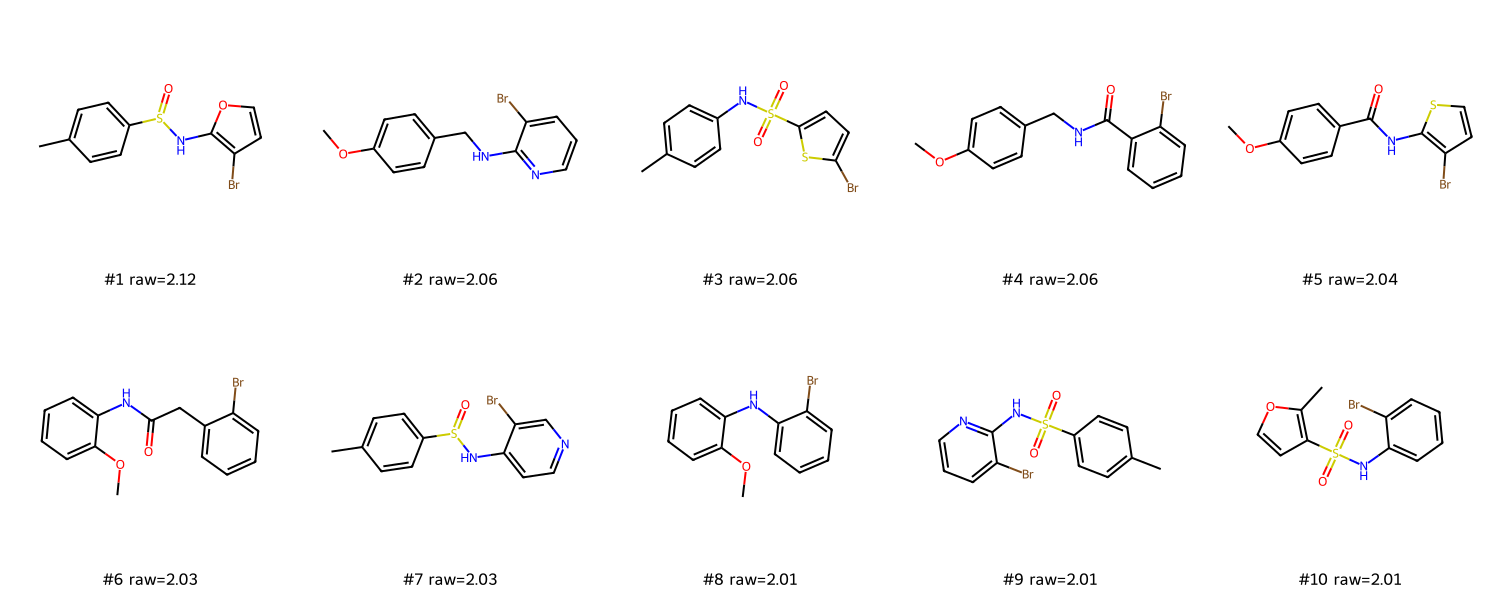

In [42]:
# Unique canonical only before drawing.
plot_df = metrics.copy()
plot_df["canonical"] = plot_df["canonical"].fillna(plot_df["smiles"]).astype(str)
plot_df = plot_df.drop_duplicates(subset=["canonical"], keep="first").reset_index(drop=True)
assert plot_df["canonical"].nunique() == len(plot_df)

mols, legends = [], []
for i, row in plot_df.iterrows():
    smi = row["canonical"]
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        continue
    mols.append(mol)
    score_key = next((k for k in ("raw_total", "quality", "reward") if pd.notna(row.get(k))), None)
    r = float(row[score_key]) if score_key else float("nan")
    legends.append(f"#{i + 1} raw={r:.2f}")

if not mols:
    raise ValueError("No valid molecules to display.")

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=MOLS_PER_ROW,
    legends=legends,
    subImgSize=(300, 300),
)
display(img)
